<a href="https://colab.research.google.com/github/MaineCalabrezi13/Classificacao-Cancer-Mama-ML/blob/main/Modelo_Complementar.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/MaineCalabrezi13/Classificacao-Cancer-Mama-ML/blob/main/Modelo_Complementar.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import sklearn
import scipy
import sys
import os
import numpy as np
import pandas as pd

print("Python:", sys.version)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("SciPy:", scipy.__version__)

# Importação de bibliotecas essenciais
import matplotlib.pyplot as plt
import seaborn as sns

# Pré-processamento e Modelagem
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (train_test_split, GridSearchCV, StratifiedKFold,
                                     RepeatedStratifiedKFold, cross_validate)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Modelos
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC

# Métricas
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay, RocCurveDisplay,
    adjusted_rand_score, normalized_mutual_info_score, silhouette_score
)
from sklearn.inspection import permutation_importance
from scipy import stats
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
from collections import Counter
from joblib import dump
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

# Não supervisionado
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 10

print("Ambiente configurado com sucesso!")

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
NumPy: 2.4.6
Pandas: 2.2.3
Scikit-learn: 1.6.1
SciPy: 1.16.3
Ambiente configurado com sucesso!


In [2]:
# Célula 2: Carga, Inspeção e Estruturação do Dataset
data = load_breast_cancer(as_frame=True)
df = data.frame
features_num = data.feature_names

# ATENÇÃO: no scikit-learn, o target original é 0 = maligno e 1 = benigno.
# Aqui o target é remapeado para 1 = Maligno (classe POSITIVA) e 0 = Benigno.
# Essa convenção vale para todas as métricas, matrizes de confusão e gráficos.
df['diagnosis_numeric'] = df['target'].map({0: 1, 1: 0})
df['diagnosis_label'] = df['diagnosis_numeric'].map({1: 'Maligno', 0: 'Benigno'})

print("Dataset carregado com sucesso!")
print(f"Dimensões do dataset: {df.shape[0]} linhas e {df.shape[1]} colunas.")

Dataset carregado com sucesso!
Dimensões do dataset: 569 linhas e 33 colunas.


=== 1. TIPOS DE DADOS E ESTRUTURA ===
float64    30
int64       2
object      1
Name: count, dtype: int64

=== 2. VERIFICAÇÃO DE VALORES AUSENTES ===
Empty DataFrame
Columns: [Qtd_Nulos, Pct_Nulos (%)]
Index: []
Total de valores nulos no dataset inteiro: 0

=== 3. VERIFICAÇÃO DE DUPLICATAS ===
Linhas completamente duplicadas: 0
Registros duplicados considerando apenas os atributos: 0
Observação: as duplicatas são identificadas, mas não são removidas automaticamente.

=== 4. DISTRIBUIÇÃO DA VARIÁVEL-ALVO (DIAGNÓSTICO) ===
                 Contagem  Percentual (%)
diagnosis_label                          
Benigno               357           62.74
Maligno               212           37.26

=== 5. ANÁLISE QUANTITATIVA DE OUTLIERS (MÉTODO IQR) ===


,Atributo,Limite inferior,Limite superior,Quantidade de outliers,Percentual (%)
13,area error,-23.160000,86.200000,65,11.42
10,radius error,-0.137350,0.848650,38,6.68
12,perimeter error,-1.020500,5.983500,38,6.68
23,worst area,-337.750000,1937.050000,35,6.15
14,smoothness error,0.000703,0.012612,30,5.27
19,fractal dimension error,-0.001217,0.008023,28,4.92
15,compactness error,-0.015975,0.061505,28,4.92
18,symmetry error,0.002680,0.035960,27,4.75
3,mean area,-123.300000,1326.300000,25,4.39
29,worst fractal dimension,0.040530,0.123010,24,4.22



=== 6. RESUMO GERAL DOS OUTLIERS ===
Total de atributos analisados: 30
Atributos com pelo menos um outlier: 29
Maior quantidade de outliers em um atributo: 65
Atributo com maior quantidade de outliers: area error


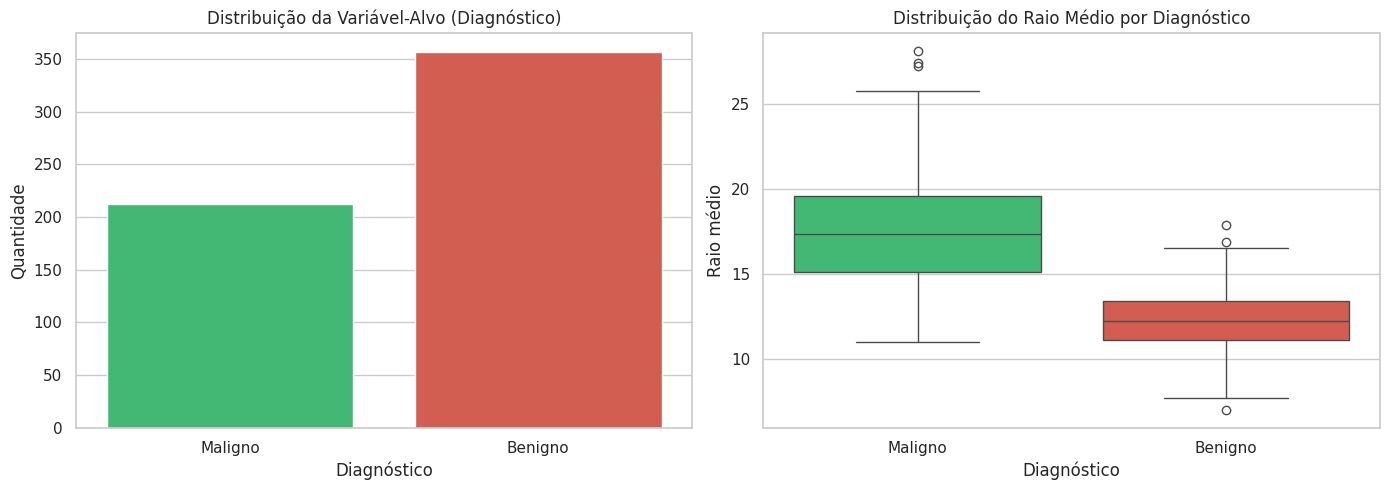

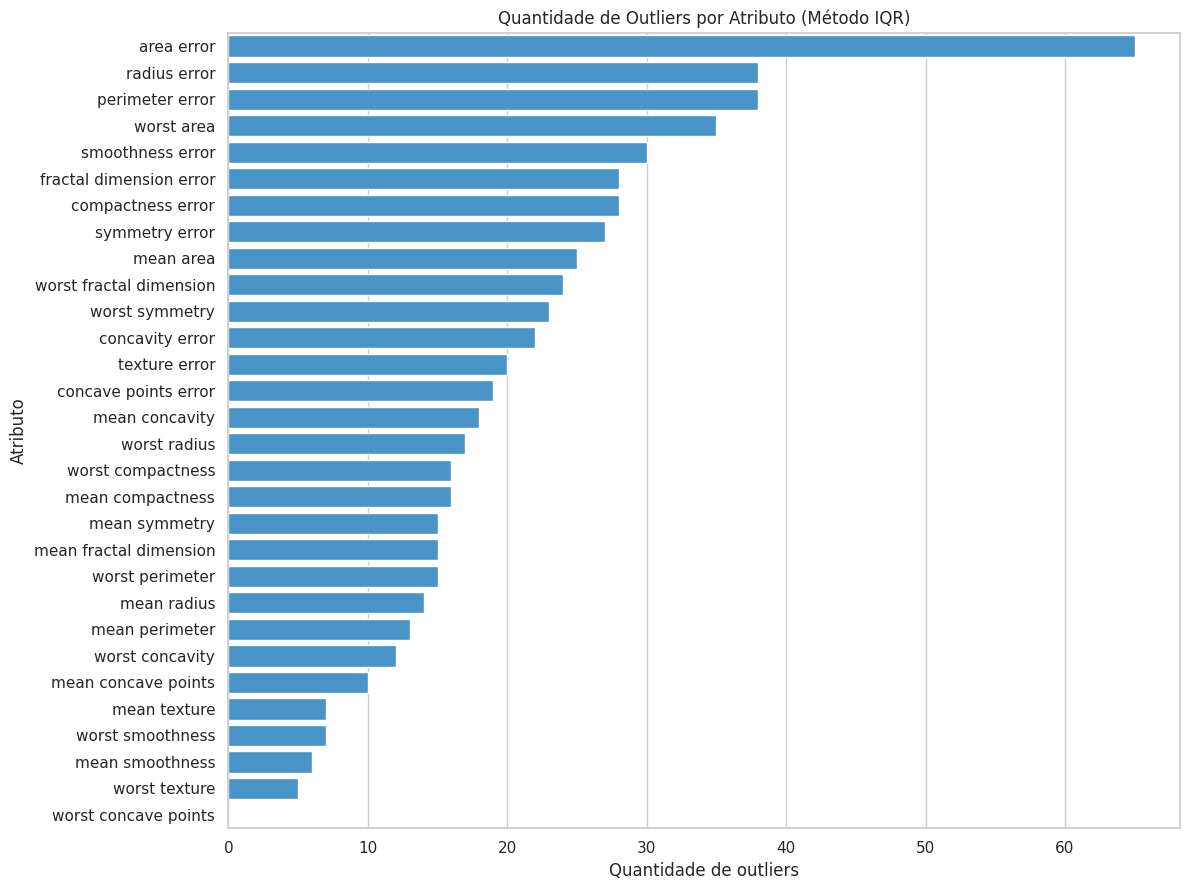

In [3]:
# Célula 3: Análise Exploratória de Dados (EDA)

print("=== 1. TIPOS DE DADOS E ESTRUTURA ===")
print(df.dtypes.value_counts())

print("\n=== 2. VERIFICAÇÃO DE VALORES AUSENTES ===")
nulos = df.isnull().sum()
pct_nulos = (nulos / len(df)) * 100

df_nulos = pd.DataFrame({
    'Qtd_Nulos': nulos,
    'Pct_Nulos (%)': pct_nulos
})

print(df_nulos[df_nulos['Qtd_Nulos'] > 0])
print("Total de valores nulos no dataset inteiro:", df.isnull().sum().sum())


print("\n=== 3. VERIFICAÇÃO DE DUPLICATAS ===")

# Duplicatas considerando todas as colunas
duplicatas_totais = df.duplicated().sum()

# Seleciona exclusivamente os 30 atributos preditores originais.
# Isso evita incluir target e diagnosis_numeric (duas representações do diagnóstico)
# na análise de duplicatas e de outliers.
atributos_numericos = list(features_num)

# Duplicatas considerando somente os atributos preditores
duplicatas_atributos = df[atributos_numericos].duplicated().sum()

print("Linhas completamente duplicadas:", duplicatas_totais)
print("Registros duplicados considerando apenas os atributos:", duplicatas_atributos)

print("Observação: as duplicatas são identificadas, mas não são removidas automaticamente.")


print("\n=== 4. DISTRIBUIÇÃO DA VARIÁVEL-ALVO (DIAGNÓSTICO) ===")

dist_target = df['diagnosis_label'].value_counts()
pct_target = df['diagnosis_label'].value_counts(normalize=True) * 100

print(pd.DataFrame({
    'Contagem': dist_target,
    'Percentual (%)': pct_target.round(2)
}))


print("\n=== 5. ANÁLISE QUANTITATIVA DE OUTLIERS (MÉTODO IQR) ===")

resultados_outliers = []

for coluna in atributos_numericos:
    q1 = df[coluna].quantile(0.25)
    q3 = df[coluna].quantile(0.75)
    iqr = q3 - q1

    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    mascara_outliers = (
        (df[coluna] < limite_inferior) |
        (df[coluna] > limite_superior)
    )

    quantidade = mascara_outliers.sum()
    percentual = (quantidade / len(df)) * 100

    resultados_outliers.append({
        'Atributo': coluna,
        'Limite inferior': limite_inferior,
        'Limite superior': limite_superior,
        'Quantidade de outliers': quantidade,
        'Percentual (%)': round(percentual, 2)
    })

df_outliers = pd.DataFrame(resultados_outliers)

df_outliers = df_outliers.sort_values(
    by='Quantidade de outliers',
    ascending=False
)

display(df_outliers)


print("\n=== 6. RESUMO GERAL DOS OUTLIERS ===")

total_atributos_analisados = len(atributos_numericos)
atributos_com_outliers = (
    df_outliers['Quantidade de outliers'] > 0
).sum()

print("Total de atributos analisados:", total_atributos_analisados)
print("Atributos com pelo menos um outlier:", atributos_com_outliers)

print(
    "Maior quantidade de outliers em um atributo:",
    df_outliers['Quantidade de outliers'].max()
)

print(
    "Atributo com maior quantidade de outliers:",
    df_outliers.iloc[0]['Atributo']
)


# ============================================================
# 7. VISUALIZAÇÕES DA ANÁLISE EXPLORATÓRIA
# ============================================================

# Distribuição da variável-alvo e boxplot do raio médio
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(
    x='diagnosis_label',
    data=df,
    ax=axes[0],
    hue='diagnosis_label',
    palette=['#2ecc71', '#e74c3c'],
    legend=False
)
axes[0].set_title('Distribuição da Variável-Alvo (Diagnóstico)')
axes[0].set_xlabel('Diagnóstico')
axes[0].set_ylabel('Quantidade')

sns.boxplot(
    x='diagnosis_label',
    y='mean radius',
    data=df,
    ax=axes[1],
    hue='diagnosis_label',
    palette=['#2ecc71', '#e74c3c'],
    legend=False
)
axes[1].set_title('Distribuição do Raio Médio por Diagnóstico')
axes[1].set_xlabel('Diagnóstico')
axes[1].set_ylabel('Raio médio')

plt.tight_layout()
plt.show()


# ============================================================
# 8. VISUALIZAÇÃO DA QUANTIDADE DE OUTLIERS POR ATRIBUTO
# ============================================================

plt.figure(figsize=(12, 9))

sns.barplot(
    data=df_outliers,
    x='Quantidade de outliers',
    y='Atributo',
    color='#3498db'
)

plt.title('Quantidade de Outliers por Atributo (Método IQR)')
plt.xlabel('Quantidade de outliers')
plt.ylabel('Atributo')
plt.tight_layout()
plt.show()


In [4]:
# Célula 4: Pré-processamento e Divisão em Treino, Validação e Teste
X = df[features_num].copy()
y = df['diagnosis_numeric'].copy()

# Divisão inicial: Separa 20% para Teste final e 80% para (Treino + Validação)
X_train_val, X_test_raw, y_train_val, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Divide os 80% restantes em Treino (60% do total) e Validação (20% do total)
X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.25, random_state=42, stratify=y_train_val
)

print(f"Dimensões do Conjunto de Treino: {X_train_raw.shape}")
print(f"Dimensões do Conjunto de Validação: {X_val_raw.shape}")
print(f"Dimensões do Conjunto de Teste: {X_test_raw.shape}")

Dimensões do Conjunto de Treino: (341, 30)
Dimensões do Conjunto de Validação: (114, 30)
Dimensões do Conjunto de Teste: (114, 30)


k = 2 | Silhouette: 0.3462 | Inércia: 6856.86
k = 3 | Silhouette: 0.3137 | Inércia: 5963.06
k = 4 | Silhouette: 0.2880 | Inércia: 5463.11
k = 5 | Silhouette: 0.1593 | Inércia: 5034.81
k = 6 | Silhouette: 0.1638 | Inércia: 4684.62
Melhor K entre os testados (2, 3, 4, 5, 6): K = 2 (Silhouette = 0.3462). Este valor NÃO é usado nos modelos.

=== Silhouette por K testado (treino, exploratório) ===


,Silhouette,Inércia,Melhor K (Silhouette)
K,,,
2,0.3462,6856.86,◄
3,0.3137,5963.06,
4,0.2880,5463.11,
5,0.1593,5034.81,
6,0.1638,4684.62,


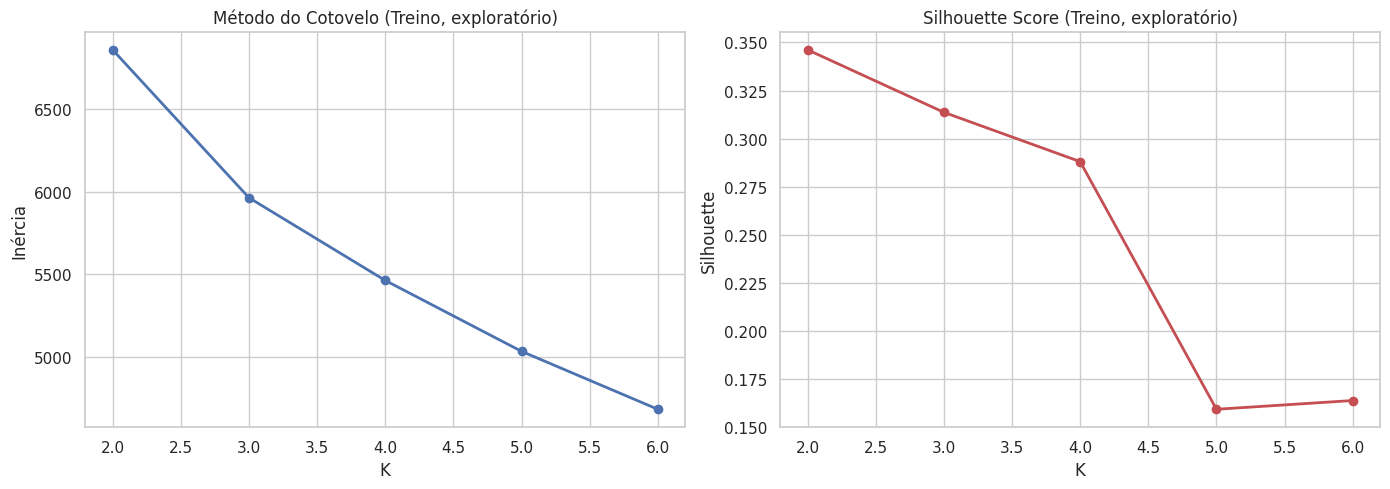

ARI (clusters x diagnóstico): 0.6473
NMI (clusters x diagnóstico): 0.5246


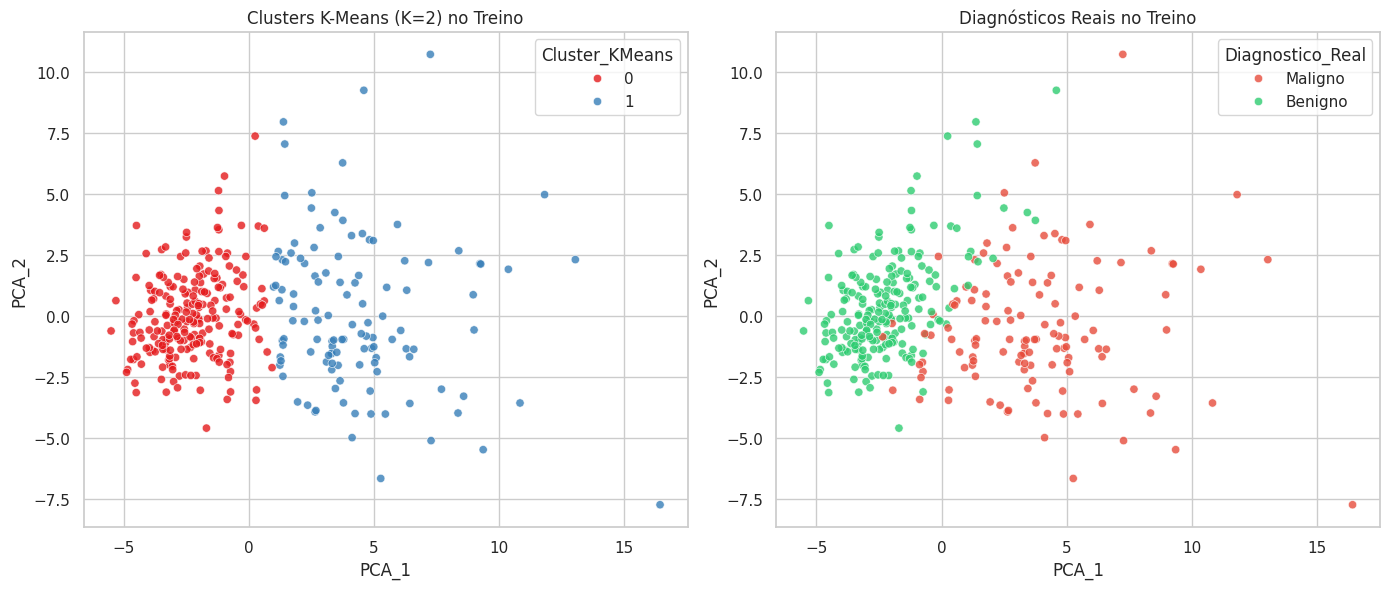


Pipelines definidos: cenário 'Sem K-Means' (30 features) e 'Com K-Means' (30 + distâncias K-Means, K escolhido por fold).


In [5]:
# Célula 5: Aprendizado não supervisionado
#   (a) Análise EXPLORATÓRIA de K e PCA (somente treino, apenas para visualização/relatório)
#   (b) Transformador K-Means que ESCOLHE K DENTRO de cada fold (sem vazamento)
#
# IMPORTANTE: o K usado nos modelos NÃO vem da análise exploratória (a). Ele é escolhido
# por Silhouette dentro do método fit() do transformador, usando apenas os dados de treino
# daquele fold. Assim, nenhuma amostra do fold de validação influencia o K.

K_RANGE = (2, 3, 4, 5, 6)

# ---------- (a) Exploração (treino) ----------
scaler_explor = StandardScaler()
X_train_scaled = scaler_explor.fit_transform(X_train_raw)

silhouette_scores, inertia = [], []
for k in K_RANGE:
    km_test = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km_test.fit_predict(X_train_scaled)
    silhouette_scores.append(silhouette_score(X_train_scaled, labels))
    inertia.append(km_test.inertia_)
    print(f"k = {k} | Silhouette: {silhouette_scores[-1]:.4f} | Inércia: {km_test.inertia_:.2f}")

k_explor = K_RANGE[int(np.argmax(silhouette_scores))]
print(f"Melhor K entre os testados {K_RANGE}: K = {k_explor} "
      f"(Silhouette = {max(silhouette_scores):.4f}). Este valor NÃO é usado nos modelos.")

# Tabela com Silhouette e Inércia por K (exploratório, apenas treino)
df_sil = pd.DataFrame({
    "K": list(K_RANGE),
    "Silhouette": np.round(silhouette_scores, 4),
    "Inércia": np.round(inertia, 2),
})
df_sil["Melhor K (Silhouette)"] = np.where(df_sil["K"] == k_explor, "◄", "")
print("\n=== Silhouette por K testado (treino, exploratório) ===")
display(df_sil.set_index("K"))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(K_RANGE, inertia, 'bo-', linewidth=2)
axes[0].set_title('Método do Cotovelo (Treino, exploratório)'); axes[0].set_xlabel('K'); axes[0].set_ylabel('Inércia')
axes[1].plot(K_RANGE, silhouette_scores, 'ro-', linewidth=2)
axes[1].set_title('Silhouette Score (Treino, exploratório)'); axes[1].set_xlabel('K'); axes[1].set_ylabel('Silhouette')
plt.tight_layout(); plt.show()

# Concordância clusters x diagnóstico (análise complementar; não usada para escolher K)
kmeans_viz = KMeans(n_clusters=k_explor, random_state=42, n_init=20).fit(X_train_scaled)
print(f"ARI (clusters x diagnóstico): {adjusted_rand_score(y_train, kmeans_viz.labels_):.4f}")
print(f"NMI (clusters x diagnóstico): {normalized_mutual_info_score(y_train, kmeans_viz.labels_):.4f}")

pca = PCA(n_components=2, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)
df_pca = pd.DataFrame(X_train_pca, columns=['PCA_1', 'PCA_2'])
df_pca['Cluster_KMeans'] = kmeans_viz.labels_
df_pca['Diagnostico_Real'] = y_train.map({0: 'Benigno', 1: 'Maligno'}).values

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.scatterplot(x='PCA_1', y='PCA_2', hue='Cluster_KMeans', data=df_pca, palette='Set1', ax=axes[0], alpha=0.8)
axes[0].set_title(f'Clusters K-Means (K={k_explor}) no Treino')
sns.scatterplot(x='PCA_1', y='PCA_2', hue='Diagnostico_Real', data=df_pca,
                palette={'Benigno': '#2ecc71', 'Maligno': '#e74c3c'}, ax=axes[1], alpha=0.8)
axes[1].set_title('Diagnósticos Reais no Treino')
plt.tight_layout(); plt.show()

# ---------- (b) Transformador com seleção de K interna ----------
class ClusterDistanceFeatures(BaseEstimator, TransformerMixin):
    """Concatena às features originais as distâncias aos centroides do K-Means.

    No fit(), escolhe K em `k_range` pelo maior Silhouette, usando APENAS os dados
    recebidos (no Pipeline, a parte de treino do fold). Os rótulos y NÃO são usados.
    """
    def __init__(self, k_range=K_RANGE, n_init=10, random_state=42):
        self.k_range = k_range
        self.n_init = n_init
        self.random_state = random_state

    def fit(self, X, y=None):
        X = np.asarray(X)
        scores = {}
        for k in self.k_range:
            lab = KMeans(n_clusters=k, n_init=self.n_init, random_state=self.random_state).fit_predict(X)
            scores[k] = silhouette_score(X, lab)
        self.silhouette_by_k_ = scores
        self.selected_k_ = max(scores, key=scores.get)
        self.kmeans_ = KMeans(n_clusters=self.selected_k_, n_init=self.n_init,
                              random_state=self.random_state).fit(X)
        return self

    def transform(self, X):
        X = np.asarray(X)
        return np.hstack([X, self.kmeans_.transform(X)])

class ScaleClusterDistances(BaseEstimator, TransformerMixin):
    """Padroniza somente as distâncias aos centroides, preservando os 30 atributos originais."""
    def fit(self, X, y=None):
        X = np.asarray(X)
        self.n_original_features_ = len(features_num)
        if X.shape[1] <= self.n_original_features_:
            raise ValueError("Não foram encontradas features de distância do K-Means.")
        self.distance_scaler_ = StandardScaler().fit(X[:, self.n_original_features_:])
        return self

    def transform(self, X):
        X = np.asarray(X)
        X_original = X[:, :self.n_original_features_]
        X_distancias = self.distance_scaler_.transform(X[:, self.n_original_features_:])
        return np.hstack([X_original, X_distancias])

# Construtor dos dois cenários. No cenário com K-Means, as distâncias adicionadas
# recebem uma segunda padronização própria: o SVM/RBF não fica dominado pela escala
# numérica das distâncias em relação aos atributos originais.
def build_pipeline(model, usar_kmeans):
    steps = [("scaler", StandardScaler())]
    if usar_kmeans:
        steps.extend([
            ("kmeans_feats", ClusterDistanceFeatures()),
            ("scale_cluster_distances", ScaleClusterDistances()),
        ])
    steps.append(("clf", model))
    return Pipeline(steps)

print("\nPipelines definidos: cenário 'Sem K-Means' (30 features) e 'Com K-Means' (30 + distâncias K-Means, K escolhido por fold).")


In [6]:
# Célula 6: Tuning (GridSearchCV dentro do Pipeline) e comparação Sem K-Means (30 feat.) vs Com K-Means (30 + K-Means)
# Scaler, escolha de K e K-Means são reajustados em CADA fold -> sem vazamento.
# O GridSearch usa SOMENTE o conjunto de treino (validação e teste não participam).

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

modelos_grid = {
    "Árvore de Decisão": (DecisionTreeClassifier(random_state=42),
        {"clf__max_depth": [3, 5, 7, None], "clf__min_samples_leaf": [1, 2, 5]}),
    "SVM": (SVC(probability=True, random_state=42),
        {"clf__C": [0.1, 1, 10], "clf__gamma": ["scale", 0.01, 0.1], "clf__kernel": ["rbf"]}),
    "Random Forest": (RandomForestClassifier(random_state=42),
        {"clf__n_estimators": [100, 300], "clf__max_depth": [None, 5, 10], "clf__min_samples_leaf": [1, 2]}),
    "Gradient Boosting": (GradientBoostingClassifier(random_state=42),
        {"clf__n_estimators": [100, 200], "clf__learning_rate": [0.05, 0.1], "clf__max_depth": [2, 3]}),
}

CEN_SEM = "Sem K-Means"
CEN_COM = "Com K-Means"
cenarios = {CEN_SEM: False, CEN_COM: True}
scoring = {"f1": "f1", "recall": "recall", "accuracy": "accuracy"}

melhores = {}          # (modelo, cenário) -> pipeline treinado com melhores hiperparâmetros
linhas_cv = []

for cen, usar_km in cenarios.items():
    for nome, (est, grid) in modelos_grid.items():
        pipe = build_pipeline(clone(est), usar_km)
        gs = GridSearchCV(pipe, grid, cv=cv_strategy, scoring=scoring, refit="f1", n_jobs=-1)
        gs.fit(X_train_raw, y_train)          # somente treino
        i = gs.best_index_
        melhores[(nome, cen)] = gs.best_estimator_
        linhas_cv.append({
            "Modelo": nome, "Cenário": cen,
            "F1 (CV)": f"{gs.cv_results_['mean_test_f1'][i]:.4f} (±{gs.cv_results_['std_test_f1'][i]:.4f})",
            "Recall (CV)": f"{gs.cv_results_['mean_test_recall'][i]:.4f} (±{gs.cv_results_['std_test_recall'][i]:.4f})",
            "Acurácia (CV)": f"{gs.cv_results_['mean_test_accuracy'][i]:.4f} (±{gs.cv_results_['std_test_accuracy'][i]:.4f})"
        })
        extra = ""
        if usar_km:
            extra = f" | K escolhido no treino completo: {gs.best_estimator_.named_steps['kmeans_feats'].selected_k_}"
        print(f"OK: {nome} | {cen}{extra}")

df_cv = pd.DataFrame(linhas_cv)
pd.set_option("display.max_colwidth", None)
print("\n=== VALIDAÇÃO CRUZADA (5-fold, somente treino, hiperparâmetros otimizados) ===")
display(df_cv)

OK: Árvore de Decisão | Sem K-Means
OK: SVM | Sem K-Means
OK: Random Forest | Sem K-Means
OK: Gradient Boosting | Sem K-Means
OK: Árvore de Decisão | Com K-Means | K escolhido no treino completo: 2
OK: SVM | Com K-Means | K escolhido no treino completo: 2
OK: Random Forest | Com K-Means | K escolhido no treino completo: 2
OK: Gradient Boosting | Com K-Means | K escolhido no treino completo: 2

=== VALIDAÇÃO CRUZADA (5-fold, somente treino, hiperparâmetros otimizados) ===


,Modelo,Cenário,F1 (CV),Recall (CV),Acurácia (CV)
0,Árvore de Decisão,Sem K-Means,0.9457 (±0.0145),0.9606 (±0.0243),0.9590 (±0.0110)
1,SVM,Sem K-Means,0.9637 (±0.0266),0.9452 (±0.0395),0.9737 (±0.0192)
2,Random Forest,Sem K-Means,0.9365 (±0.0291),0.9298 (±0.0661),0.9532 (±0.0214)
3,Gradient Boosting,Sem K-Means,0.9675 (±0.0284),0.9532 (±0.0564),0.9766 (±0.0196)
4,Árvore de Decisão,Com K-Means,0.9457 (±0.0145),0.9606 (±0.0243),0.9590 (±0.0110)
5,SVM,Com K-Means,0.9642 (±0.0264),0.9532 (±0.0376),0.9737 (±0.0192)
6,Random Forest,Com K-Means,0.9250 (±0.0268),0.9138 (±0.0561),0.9443 (±0.0214)
7,Gradient Boosting,Com K-Means,0.9675 (±0.0284),0.9532 (±0.0564),0.9766 (±0.0196)


In [7]:
# Célula 6B — Calibração do limiar por previsões OOF com busca aninhada de hiperparâmetros
# Em cada fold OOF, a busca de hiperparâmetros é refeita somente nos folds internos
# do subconjunto de treinamento. O fold OOF fica totalmente isolado até a predição.
# Assim, a amostra prevista não participa nem do ajuste do modelo nem da escolha
# dos hiperparâmetros usados para gerar sua própria probabilidade.
# Validação e teste não participam da calibração do limiar.

ALVOS_RECALL = [1.00, 0.98, 0.975, 0.95]
ALVO_RECALL = 0.98  # meta principal definida antes da avaliação no teste

# Os mesmos folds externos são usados para todos os modelos/cenários.
# A busca interna usa 3 folds para reduzir o custo computacional.
cv_oof_externo = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_oof_interno = StratifiedKFold(n_splits=3, shuffle=True, random_state=123)
splits_oof = list(cv_oof_externo.split(X_train_raw, y_train))

y_oof = np.asarray(y_train)
limiares = {}
dados_cal = {}
linhas_lim = []
parametros_oof = {}

for (nome, cen), usar_km in [
    ((nome, cen), usar_km)
    for cen, usar_km in cenarios.items()
    for nome in modelos_grid
]:
    estimador, grade = modelos_grid[nome]
    proba_oof = np.full(len(X_train_raw), np.nan, dtype=float)
    escolhas_fold = []

    for numero_fold, (idx_treino, idx_oof) in enumerate(splits_oof, start=1):
        X_treino_fold = X_train_raw.iloc[idx_treino]
        y_treino_fold = y_train.iloc[idx_treino]
        X_oof_fold = X_train_raw.iloc[idx_oof]

        busca = GridSearchCV(
            estimator=build_pipeline(clone(estimador), usar_km),
            param_grid=grade,
            scoring='f1',
            refit=True,
            cv=cv_oof_interno,
            n_jobs=-1
        )
        busca.fit(X_treino_fold, y_treino_fold)
        proba_oof[idx_oof] = busca.predict_proba(X_oof_fold)[:, 1]
        escolhas_fold.append(busca.best_params_)

    if np.isnan(proba_oof).any():
        raise RuntimeError(f"Há previsões OOF ausentes para {nome} | {cen}.")

    dados_cal[(nome, cen)] = (y_oof.copy(), proba_oof.copy())
    parametros_oof[(nome, cen)] = escolhas_fold

    # Testa limiares observados na classe positiva (Maligno = 1).
    candidatos = np.unique(proba_oof[y_oof == 1])

    for alvo in ALVOS_RECALL:
        resultados = []
        for limiar in candidatos:
            pred = (proba_oof >= limiar).astype(int)
            tn, fp, fn, tp = confusion_matrix(y_oof, pred, labels=[0, 1]).ravel()
            recall = tp / (tp + fn) if (tp + fn) else 0.0

            if recall >= alvo:
                resultados.append({
                    'Limiar': float(limiar),
                    'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp),
                    'Recall': recall,
                    'Precisão': precision_score(y_oof, pred, pos_label=1, zero_division=0),
                    'F1': f1_score(y_oof, pred, zero_division=0)
                })

        if resultados:
            # Maior limiar que ainda atende à meta: reduz FP sem violar o recall-alvo.
            melhor = max(resultados, key=lambda x: x['Limiar'])
            linhas_lim.append({
                'Modelo': nome, 'Cenário': cen, 'Recall alvo': alvo, **melhor
            })
            if np.isclose(alvo, ALVO_RECALL):
                limiares[(nome, cen)] = melhor['Limiar']

    print(f"OOF concluído: {nome} | {cen} — 5 folds externos; busca interna de 3 folds.")

df_lim = pd.DataFrame(linhas_lim)
print("\n=== COMPARAÇÃO DOS LIMIARES POR META DE RECALL (OOF ANINHADO) ===")
display(df_lim.sort_values(['Recall alvo', 'F1'], ascending=[False, False]).round(4))

print(f"\n=== LIMIARES SELECIONADOS PARA RECALL MÍNIMO DE {ALVO_RECALL:.1%} ===")
display(
    df_lim[np.isclose(df_lim['Recall alvo'], ALVO_RECALL)]
    .sort_values('F1', ascending=False)
    .round(4)
)

print("\nCada previsão OOF foi gerada por uma busca de hiperparâmetros que não utilizou aquela amostra.")
print("A validação será usada posteriormente para selecionar o modelo final.")
print("O conjunto de teste permanece reservado exclusivamente para avaliação final.")


OOF concluído: Árvore de Decisão | Sem K-Means — 5 folds externos; busca interna de 3 folds.
OOF concluído: SVM | Sem K-Means — 5 folds externos; busca interna de 3 folds.
OOF concluído: Random Forest | Sem K-Means — 5 folds externos; busca interna de 3 folds.
OOF concluído: Gradient Boosting | Sem K-Means — 5 folds externos; busca interna de 3 folds.
OOF concluído: Árvore de Decisão | Com K-Means — 5 folds externos; busca interna de 3 folds.
OOF concluído: SVM | Com K-Means — 5 folds externos; busca interna de 3 folds.
OOF concluído: Random Forest | Com K-Means — 5 folds externos; busca interna de 3 folds.
OOF concluído: Gradient Boosting | Com K-Means — 5 folds externos; busca interna de 3 folds.

=== COMPARAÇÃO DOS LIMIARES POR META DE RECALL (OOF ANINHADO) ===


,Modelo,Cenário,Recall alvo,Limiar,TN,FP,FN,TP,Recall,Precisão,F1
12,Gradient Boosting,Sem K-Means,1.000,0.0002,95,119,0,127,1.0000,0.5163,0.6810
4,SVM,Sem K-Means,1.000,0.0037,85,129,0,127,1.0000,0.4961,0.6632
20,SVM,Com K-Means,1.000,0.0042,84,130,0,127,1.0000,0.4942,0.6615
28,Gradient Boosting,Com K-Means,1.000,0.0000,26,188,0,127,1.0000,0.4032,0.5747
0,Árvore de Decisão,Sem K-Means,1.000,0.0000,0,214,0,127,1.0000,0.3724,0.5427
8,Random Forest,Sem K-Means,1.000,0.0000,0,214,0,127,1.0000,0.3724,0.5427
16,Árvore de Decisão,Com K-Means,1.000,0.0000,0,214,0,127,1.0000,0.3724,0.5427
24,Random Forest,Com K-Means,1.000,0.0000,0,214,0,127,1.0000,0.3724,0.5427
5,SVM,Sem K-Means,0.980,0.2897,206,8,2,125,0.9843,0.9398,0.9615
21,SVM,Com K-Means,0.980,0.2717,202,12,2,125,0.9843,0.9124,0.9470



=== LIMIARES SELECIONADOS PARA RECALL MÍNIMO DE 98.0% ===


,Modelo,Cenário,Recall alvo,Limiar,TN,FP,FN,TP,Recall,Precisão,F1
5,SVM,Sem K-Means,0.98,0.2897,206,8,2,125,0.9843,0.9398,0.9615
21,SVM,Com K-Means,0.98,0.2717,202,12,2,125,0.9843,0.9124,0.9470
25,Random Forest,Com K-Means,0.98,0.2900,197,17,2,125,0.9843,0.8803,0.9294
9,Random Forest,Sem K-Means,0.98,0.2400,195,19,2,125,0.9843,0.8681,0.9225
29,Gradient Boosting,Com K-Means,0.98,0.0307,195,19,2,125,0.9843,0.8681,0.9225
13,Gradient Boosting,Sem K-Means,0.98,0.0436,190,24,2,125,0.9843,0.8389,0.9058
17,Árvore de Decisão,Com K-Means,0.98,0.0064,156,58,2,125,0.9843,0.6831,0.8065
1,Árvore de Decisão,Sem K-Means,0.98,0.0000,0,214,0,127,1.0000,0.3724,0.5427



Cada previsão OOF foi gerada por uma busca de hiperparâmetros que não utilizou aquela amostra.
A validação será usada posteriormente para selecionar o modelo final.
O conjunto de teste permanece reservado exclusivamente para avaliação final.


=== RESULTADOS: TREINO x VALIDAÇÃO (limiar 0.5) ===


,Modelo,Cenário,Conjunto,Acurácia,Precisão,Recall,F1-Score,ROC-AUC,Limiar,TN,FP,FN,TP
14,Gradient Boosting,Com K-Means,Treino,1.0000,1.0000,1.0000,1.0000,1.0000,0.5,214,0,0,127
15,Gradient Boosting,Com K-Means,Validação,0.9386,0.8913,0.9535,0.9213,0.9944,0.5,66,5,2,41
6,Gradient Boosting,Sem K-Means,Treino,1.0000,1.0000,1.0000,1.0000,1.0000,0.5,214,0,0,127
7,Gradient Boosting,Sem K-Means,Validação,0.9386,0.8913,0.9535,0.9213,0.9925,0.5,66,5,2,41
12,Random Forest,Com K-Means,Treino,0.9941,1.0000,0.9843,0.9921,0.9999,0.5,214,0,2,125
13,Random Forest,Com K-Means,Validação,0.9649,0.9535,0.9535,0.9535,0.9889,0.5,69,2,2,41
4,Random Forest,Sem K-Means,Treino,1.0000,1.0000,1.0000,1.0000,1.0000,0.5,214,0,0,127
5,Random Forest,Sem K-Means,Validação,0.9737,0.9762,0.9535,0.9647,0.9918,0.5,70,1,2,41
10,SVM,Com K-Means,Treino,0.9883,1.0000,0.9685,0.9840,0.9977,0.5,214,0,4,123
11,SVM,Com K-Means,Validação,0.9649,0.9333,0.9767,0.9545,0.9957,0.5,68,3,1,42



>>> MODELO ESCOLHIDO PELA VALIDAÇÃO: SVM | Com K-Means
>>> Critério: F1-Score, depois Recall e depois ROC-AUC (com limiar ajustado).


,Modelo,Cenário,Limiar,Precisão,Recall,F1-Score,ROC-AUC,FP,FN
0,SVM,Com K-Means,0.2717,0.9130,0.9767,0.9438,0.9957,4,1
1,SVM,Sem K-Means,0.2897,0.8936,0.9767,0.9333,0.9957,5,1
2,Random Forest,Com K-Means,0.2900,0.8723,0.9535,0.9111,0.9889,6,2
3,Gradient Boosting,Com K-Means,0.0307,0.8400,0.9767,0.9032,0.9944,8,1
4,Random Forest,Sem K-Means,0.2400,0.8400,0.9767,0.9032,0.9918,8,1
5,Gradient Boosting,Sem K-Means,0.0436,0.7925,0.9767,0.8750,0.9925,11,1
6,Árvore de Decisão,Com K-Means,0.0064,0.7778,0.9767,0.8660,0.9512,12,1
7,Árvore de Decisão,Sem K-Means,0.0000,0.3772,1.0000,0.5478,0.9387,71,0


>>> Limiar de decisão ajustado (meta OOF de recall = 98%): 0.2717
>>> O modelo final e o limiar estão CONGELADOS.

=== CUSTO DO RECALL: limiar x FN/FP (calibração) ===


,Recall alvo,Limiar,FN,FP,Precisão,F1
0,1.00,0.0042,0,130,0.4942,0.6615
1,0.99,0.0385,1,51,0.7119,0.8289
2,0.98,0.2717,2,12,0.9124,0.9470
3,0.95,0.5857,6,4,0.9680,0.9603


... (5 outputs left out)

,Acurácia,Precisão,Recall,F1-Score,ROC-AUC,Limiar,TN,FP,FN,TP
0,0.9474,0.8913,0.9762,0.9318,0.9957,0.27169,67,5,1,41



=== INTERVALOS DE CONFIANÇA BOOTSTRAP (95%) ===


,Métrica,Estimativa,IC 95% inferior,IC 95% superior
0,Acurácia,0.9474,0.9035,0.9825
1,Precisão,0.8913,0.8077,0.9762
2,Recall,0.9762,0.9286,1.0000
3,F1-Score,0.9318,0.8791,0.9767
4,ROC-AUC,0.9957,0.9851,1.0000


Recall no teste = 41/42 | IC 95% exato (Clopper-Pearson): [0.8743, 0.9994]
Com poucos malignos no teste, recall = 1 NÃO garante recall = 1 em dados novos; o IC acima mostra a incerteza.

=== RELATÓRIO DE CLASSIFICAÇÃO ===
              precision    recall  f1-score   support

     Benigno     0.9853    0.9306    0.9571        72
     Maligno     0.8913    0.9762    0.9318        42

    accuracy                         0.9474       114
   macro avg     0.9383    0.9534    0.9445       114
weighted avg     0.9507    0.9474    0.9478       114

Falsos negativos (malignos classificados como benignos): 1 | Falsos positivos: 5


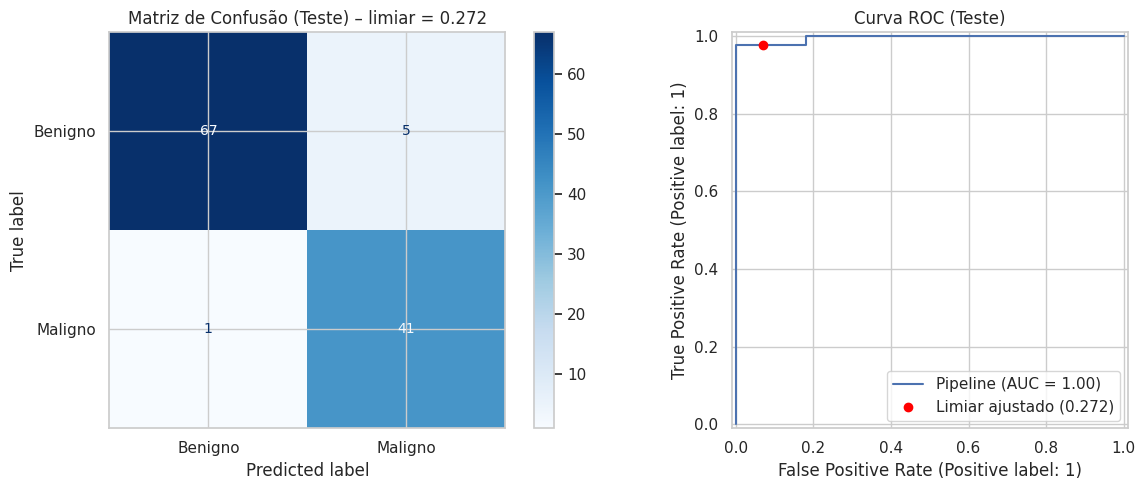

Limiar salvo em: /content/limiar_decisao.json

Pipeline final salvo em: /content/modelo_final_cancer_mama.joblib

=== COMPARAÇÃO SEM K-MEANS x COM K-MEANS NA VALIDAÇÃO ===


F1-Score                  Recall            
Cenário           Com K-Means Sem K-Means Com K-Means Sem K-Means
Modelo                                                           
Gradient Boosting      0.9213      0.9213      0.9535      0.9535
Random Forest          0.9535      0.9647      0.9535      0.9535
SVM                    0.9545      0.9545      0.9767      0.9767
Árvore de Decisão      0.8837      0.8764      0.8837      0.9070


OBSERVAÇÃO: o conjunto de teste foi utilizado para avaliação dos modelos, não para selecionar o vencedor.


In [8]:
# Célula 7: Métricas, seleção pela VALIDAÇÃO e avaliação final no TESTE
# O modelo final é escolhido exclusivamente pela validação.
# O teste dos 8 modelos é apresentado apenas para comparação descritiva.

REPORTAR_TESTE_TODOS = True

def calcular_metricas(pipe, X, y, limiar=0.5):
    y_proba = pipe.predict_proba(X)[:, 1]  # Classe positiva: Maligno (1)
    y_pred = (y_proba >= limiar).astype(int)  # limiar de decisão (0.5 = padrão)

    tn, fp, fn, tp = confusion_matrix(
        y, y_pred, labels=[0, 1]
    ).ravel()

    return {
        "Acurácia": accuracy_score(y, y_pred),
        "Precisão": precision_score(y, y_pred, pos_label=1, zero_division=0),
        "Recall": recall_score(y, y_pred, pos_label=1, zero_division=0),
        "F1-Score": f1_score(y, y_pred, pos_label=1, zero_division=0),
        "ROC-AUC": roc_auc_score(y, y_proba),
        "Limiar": limiar,
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp)
    }


def tabela_metricas(conjuntos, ajustado=False):
    linhas = []

    for (nome, cen), pipe in melhores.items():
        lim = limiares[(nome, cen)] if ajustado else 0.5
        for conj, (X_, y_) in conjuntos.items():
            metricas = calcular_metricas(pipe, X_, y_, limiar=lim)

            linhas.append({
                "Modelo": nome,
                "Cenário": cen,
                "Conjunto": conj,
                **metricas
            })

    return pd.DataFrame(linhas)


# ============================================================
# 1) AVALIAÇÃO NO TREINO E NA VALIDAÇÃO (limiar padrão 0.5)
# ============================================================

df_tv = tabela_metricas({
    "Treino": (X_train_raw, y_train),
    "Validação": (X_val_raw, y_val)
})

cols_num = [
    "Acurácia",
    "Precisão",
    "Recall",
    "F1-Score",
    "ROC-AUC"
]

print("=== RESULTADOS: TREINO x VALIDAÇÃO (limiar 0.5) ===")

display(
    df_tv.sort_values(
        ["Modelo", "Cenário", "Conjunto"]
    ).round({c: 4 for c in cols_num})
)


# ============================================================
# 2) ESCOLHA DO MODELO FINAL PELA VALIDAÇÃO
# ============================================================

# True : escolhe o modelo pelo F1 na validação com o limiar calibrado no treino OOF,
#        cuja meta principal é ALVO_RECALL (98%).
# False: escolhe pelo F1 com limiar padrão 0.5. A escolha do limiar nunca usa validação/teste.
SELECAO_COM_LIMIAR = True

if SELECAO_COM_LIMIAR:
    df_sel = tabela_metricas({"Validação": (X_val_raw, y_val)}, ajustado=True)
else:
    df_sel = df_tv[df_tv["Conjunto"] == "Validação"]

df_val = (
    df_sel
    .sort_values(
        ["F1-Score", "Recall", "ROC-AUC"],
        ascending=False
    )
    .reset_index(drop=True)
)

final_nome = df_val.loc[0, "Modelo"]
final_cen = df_val.loc[0, "Cenário"]

modelo_final = melhores[(final_nome, final_cen)]

print(
    f"\n>>> MODELO ESCOLHIDO PELA VALIDAÇÃO: "
    f"{final_nome} | {final_cen}"
)

print(">>> Critério: F1-Score, depois Recall e depois ROC-AUC "
      f"({'com limiar ajustado' if SELECAO_COM_LIMIAR else 'com limiar padrão 0.5'}).")
display(df_val[["Modelo", "Cenário", "Limiar", "Precisão", "Recall", "F1-Score", "ROC-AUC", "FP", "FN"]]
        .round({c: 4 for c in cols_num + ["Limiar"]}))
limiar_final = limiares[(final_nome, final_cen)]
print(f">>> Limiar de decisão ajustado (meta OOF de recall = 98%): {limiar_final:.4f}")
print(">>> O modelo final e o limiar estão CONGELADOS.")

# Custo-benefício do limiar (somente dados de calibração: treino OOF + validação; teste NÃO usado)
y_c, p_c = dados_cal[(final_nome, final_cen)]
scores_pos = np.sort(p_c[y_c == 1])[::-1]
linhas_cb = []
for alvo in [1.0, 0.99, 0.98, 0.95]:
    k = int(np.ceil(alvo * len(scores_pos)))
    lim_ = scores_pos[k - 1]
    pred_ = (p_c >= lim_).astype(int)
    tn_, fp_, fn_, tp_ = confusion_matrix(y_c, pred_, labels=[0, 1]).ravel()
    linhas_cb.append({"Recall alvo": alvo, "Limiar": round(float(lim_), 4), "FN": int(fn_), "FP": int(fp_),
                      "Precisão": round(tp_ / (tp_ + fp_), 4), "F1": round(f1_score(y_c, pred_), 4)})
print("\n=== CUSTO DO RECALL: limiar x FN/FP (calibração) ===")
display(pd.DataFrame(linhas_cb))


# ============================================================
# 3) TESTE DOS OITO MODELOS (APENAS PARA COMPARAÇÃO)
# ============================================================

if REPORTAR_TESTE_TODOS:

    df_teste_todos = tabela_metricas({
        "Teste": (X_test_raw, y_test)
    }, ajustado=True)   # cada modelo com o seu limiar calibrado para recall OOF >= 98%

    print("\n" + "=" * 75)
    print("RESULTADOS DOS OITO MODELOS NO TESTE (limiar ajustado p/ meta OOF de recall = 98%)")
    print("COMPARAÇÃO DESCRITIVA - NÃO UTILIZAR PARA ESCOLHER O MODELO")
    print("=" * 75)

    display(
        df_teste_todos
        .sort_values(["Modelo", "Cenário"])
        .drop(columns=["Conjunto"])
        .round({c: 4 for c in cols_num})
    )


# ============================================================
# 4) AVALIAÇÃO FINAL DO MODELO ESCOLHIDO
# ============================================================

# Referência: mesmo modelo com limiar padrão 0.5 (antes do ajuste)
m_teste_padrao = calcular_metricas(modelo_final, X_test_raw, y_test, limiar=0.5)
# Resultado final: com o limiar ajustado
m_teste = calcular_metricas(modelo_final, X_test_raw, y_test, limiar=limiar_final)

y_proba_final = modelo_final.predict_proba(X_test_raw)[:, 1]
y_pred_final = (y_proba_final >= limiar_final).astype(int)

# Checagem descritiva do limiar na validação (não é garantia de recall mínimo).
m_val_aj = calcular_metricas(modelo_final, X_val_raw, y_val, limiar=limiar_final)
print(f"\nValidação com limiar ajustado: FN = {m_val_aj['FN']} | FP = {m_val_aj['FP']} | "
      f"Recall = {m_val_aj['Recall']:.4f} | Precisão = {m_val_aj['Precisão']:.4f}")

print("\n=== ANTES x DEPOIS DO AJUSTE DE LIMIAR (TESTE) ===")
display(pd.DataFrame({"Limiar 0.5 (padrão)": m_teste_padrao,
                      f"Limiar ajustado ({limiar_final:.4f})": m_teste}).T
        .round({c: 4 for c in cols_num}))

print(
    f"\n=== AVALIAÇÃO FINAL DO MODELO ESCOLHIDO NO TESTE ==="
    f"\nModelo: {final_nome}"
    f"\nCenário: {final_cen}"
)

display(
    pd.DataFrame([m_teste]).round(
        {c: 4 for c in cols_num}
    )
)


# ============================================================
# 5) INTERVALOS DE CONFIANÇA BOOTSTRAP (95%)
# ============================================================

N_BOOTSTRAP = 2000
rng_boot = np.random.default_rng(42)

y_array = np.asarray(y_test)
pred_array = np.asarray(y_pred_final)
proba_array = np.asarray(y_proba_final)

idx_benigno = np.flatnonzero(y_array == 0)
idx_maligno = np.flatnonzero(y_array == 1)

metricas_bootstrap = {
    nome: []
    for nome in [
        "Acurácia",
        "Precisão",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ]
}

for _ in range(N_BOOTSTRAP):

    idx = np.concatenate([
        rng_boot.choice(
            idx_benigno,
            size=len(idx_benigno),
            replace=True
        ),
        rng_boot.choice(
            idx_maligno,
            size=len(idx_maligno),
            replace=True
        )
    ])

    y_b = y_array[idx]
    pred_b = pred_array[idx]
    proba_b = proba_array[idx]

    metricas_bootstrap["Acurácia"].append(
        accuracy_score(y_b, pred_b)
    )

    metricas_bootstrap["Precisão"].append(
        precision_score(
            y_b, pred_b, pos_label=1, zero_division=0
        )
    )

    metricas_bootstrap["Recall"].append(
        recall_score(
            y_b, pred_b, pos_label=1, zero_division=0
        )
    )

    metricas_bootstrap["F1-Score"].append(
        f1_score(
            y_b, pred_b, pos_label=1, zero_division=0
        )
    )

    metricas_bootstrap["ROC-AUC"].append(
        roc_auc_score(y_b, proba_b)
    )


linhas_ic = []

for nome, valores in metricas_bootstrap.items():

    linhas_ic.append({
        "Métrica": nome,
        "Estimativa": m_teste[nome],
        "IC 95% inferior": np.percentile(valores, 2.5),
        "IC 95% superior": np.percentile(valores, 97.5)
    })


df_ic = pd.DataFrame(linhas_ic)

print("\n=== INTERVALOS DE CONFIANÇA BOOTSTRAP (95%) ===")

display(df_ic.round(4))

# IC exato (Clopper-Pearson) para o recall: o bootstrap fica degenerado ([1, 1]) quando FN = 0
from scipy.stats import beta as _beta
tp_, fn_ = m_teste["TP"], m_teste["FN"]
cp_inf = _beta.ppf(0.025, tp_, fn_ + 1) if tp_ > 0 else 0.0
cp_sup = _beta.ppf(0.975, tp_ + 1, fn_) if fn_ > 0 else 1.0
print(f"Recall no teste = {tp_}/{tp_ + fn_} | IC 95% exato (Clopper-Pearson): [{cp_inf:.4f}, {cp_sup:.4f}]")
print("Com poucos malignos no teste, recall = 1 NÃO garante recall = 1 em dados novos; o IC acima mostra a incerteza.")


# ============================================================
# 6) RELATÓRIO DE CLASSIFICAÇÃO E MATRIZ DE CONFUSÃO
# ============================================================

print("\n=== RELATÓRIO DE CLASSIFICAÇÃO ===")

print(
    classification_report(
        y_test,
        y_pred_final,
        labels=[0, 1],
        target_names=["Benigno", "Maligno"],
        digits=4
    )
)

print(
    f"Falsos negativos (malignos classificados como benignos): "
    f"{m_teste['FN']} | "
    f"Falsos positivos: {m_teste['FP']}"
)


# ============================================================
# 7) MATRIZ DE CONFUSÃO E CURVA ROC
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_final,
    labels=[0, 1],
    display_labels=["Benigno", "Maligno"],
    cmap="Blues",
    ax=axes[0]
)

axes[0].set_title(
    f"Matriz de Confusão (Teste) – limiar = {limiar_final:.3f}"
)

RocCurveDisplay.from_estimator(
    modelo_final,
    X_test_raw,
    y_test,
    ax=axes[1]
)

# Ponto de operação do limiar ajustado sobre a curva ROC
axes[1].scatter([m_teste["FP"] / (m_teste["FP"] + m_teste["TN"])], [m_teste["Recall"]],
                color="red", zorder=5, label=f"Limiar ajustado ({limiar_final:.3f})")
axes[1].legend(loc="lower right")
axes[1].set_title("Curva ROC (Teste)")

plt.tight_layout()
plt.show()


# ============================================================
# 8) SALVAMENTO DO PIPELINE FINAL + LIMIAR
# ============================================================

CAMINHO_MODELO = "modelo_final_cancer_mama.joblib"

dump(modelo_final, CAMINHO_MODELO)

# Limiar salvo à parte (o .joblib do pipeline continua no mesmo formato de antes)
import json
CAMINHO_LIMIAR = "limiar_decisao.json"
with open(CAMINHO_LIMIAR, "w") as f:
    json.dump({"modelo": final_nome, "cenario": final_cen, "limiar": limiar_final,
               "classe_positiva": "Maligno (1)"}, f, indent=2, ensure_ascii=False)
print(f"Limiar salvo em: {os.path.abspath(CAMINHO_LIMIAR)}")

print(
    f"\nPipeline final salvo em: "
    f"{os.path.abspath(CAMINHO_MODELO)}"
)


# ============================================================
# 9) COMPARAÇÃO SEM K-MEANS x COM K-MEANS NA VALIDAÇÃO (limiar 0.5)
# ============================================================

comp = (
    df_tv[df_tv["Conjunto"] == "Validação"]
    .pivot(
        index="Modelo",
        columns="Cenário",
        values=["F1-Score", "Recall"]
    )
    .round(4)
)

print(
    "\n=== COMPARAÇÃO SEM K-MEANS x COM K-MEANS "
    "NA VALIDAÇÃO ==="
)

display(comp)

print(
    "\nOBSERVAÇÃO: o conjunto de teste foi utilizado para "
    "avaliação dos modelos, não para selecionar o vencedor."
)

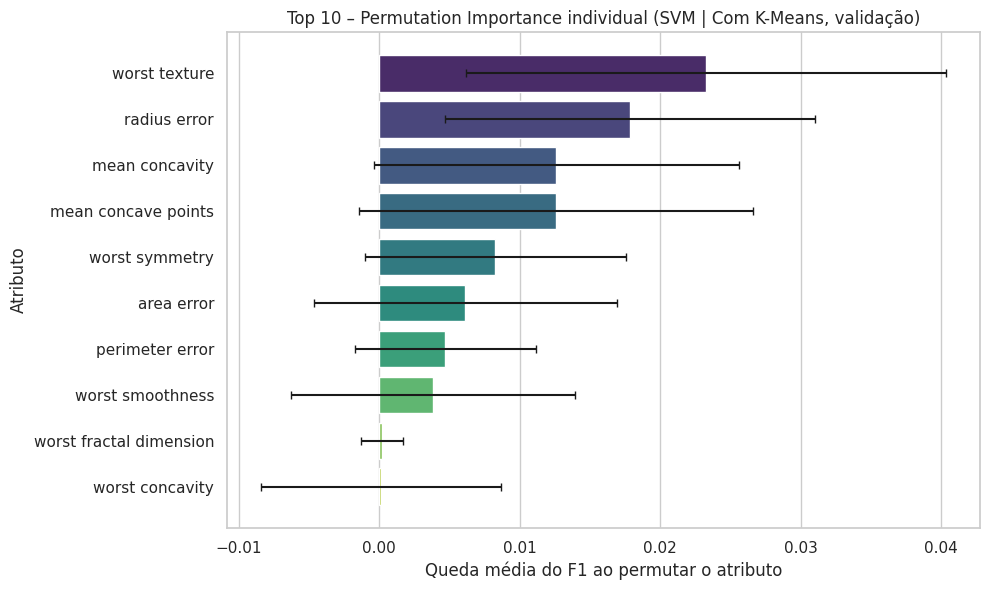

F1 de referência na validação (sem permutar): 0.9545

=== Importância por grupo de atributos correlacionados (validação; |Spearman| > 0.9 no treino) ===


,Grupo,Qtd,Queda F1 (média),Desvio
0,"mean radius, mean perimeter, mean area, worst radius, worst perimeter, worst area",6,0.1420,0.0334
5,"radius error, perimeter error, area error",3,0.0467,0.0156
3,"mean concavity, worst concavity",2,0.0450,0.0243
1,"mean texture, worst texture",2,0.0395,0.0192
4,"mean concave points, worst concave points",2,0.0220,0.0218
2,"mean compactness, worst compactness",2,-0.0037,0.0061


In [9]:
# Célula 8: Importância por permutação do modelo FINAL (já congelado)
#
# ANÁLISE APENAS INTERPRETATIVA: nenhum resultado desta célula é usado para selecionar atributos,
# trocar de modelo ou ajustar hiperparâmetros. O modelo (Célula 7) já está fixo; aqui só se explica.
#
# A importância é calculada no conjunto de VALIDAÇÃO, nunca no teste final.
# A validação já participou da escolha do modelo; portanto, esta análise é interpretativa
# e exploratória, não uma estimativa independente nem uma base para novas decisões.
# O conjunto de teste permanece reservado exclusivamente à avaliação final.
# A permutação é feita nas colunas BRUTAS; o pipeline (scaler/K-Means) reprocessa cada cópia.

X_importancia, y_importancia = X_val_raw, y_val

# (a) Importância individual
res = permutation_importance(modelo_final, X_importancia, y_importancia, n_repeats=50,
                             random_state=42, scoring="f1", n_jobs=-1)
df_imp = (pd.DataFrame({"Atributo": X_importancia.columns,
                        "Importancia": res.importances_mean,
                        "Desvio": res.importances_std})
          .sort_values("Importancia", ascending=False))

top = df_imp.head(10)
plt.figure(figsize=(10, 6))
sns.barplot(x="Importancia", y="Atributo", data=top, palette="viridis", hue="Atributo", legend=False)
plt.errorbar(top["Importancia"], range(len(top)), xerr=top["Desvio"], fmt="none", c="k", capsize=3)
plt.title(f"Top 10 – Permutation Importance individual ({final_nome} | {final_cen}, validação)")
plt.xlabel("Queda média do F1 ao permutar o atributo"); plt.tight_layout(); plt.show()

# (b) Importância por GRUPO de atributos correlacionados.
# Grupos definidos só com o TREINO (|Spearman| > 0.9). Permutar um atributo isolado subestima
# sua importância quando há colunas quase redundantes (ex.: radius, perimeter, area).
corr = X_train_raw.corr(method="spearman").abs()
dist = squareform(1 - corr.values, checks=False)
grupos_id = fcluster(linkage(dist, method="average"), t=0.1, criterion="distance")
grupos = {}
for col, g in zip(X_train_raw.columns, grupos_id):
    grupos.setdefault(g, []).append(col)
grupos = [cols for cols in grupos.values() if len(cols) > 1]

rng = np.random.default_rng(42)
f1_base = f1_score(y_importancia, modelo_final.predict(X_importancia))
linhas_g = []
for cols in grupos:
    quedas = []
    for _ in range(50):
        Xp = X_importancia.copy()
        idx = rng.permutation(len(Xp))
        Xp[cols] = Xp[cols].values[idx]          # permuta o grupo inteiro junto (preserva correlação interna)
        quedas.append(f1_base - f1_score(y_importancia, modelo_final.predict(Xp)))
    linhas_g.append({"Grupo": ", ".join(cols), "Qtd": len(cols),
                     "Queda F1 (média)": np.mean(quedas), "Desvio": np.std(quedas, ddof=1)})
df_grp = pd.DataFrame(linhas_g).sort_values("Queda F1 (média)", ascending=False)
print(f"F1 de referência na validação (sem permutar): {f1_base:.4f}")
print("\n=== Importância por grupo de atributos correlacionados (validação; |Spearman| > 0.9 no treino) ===")
display(df_grp.round(4))


In [10]:
# Célula 9: Nested Cross-Validation – comparação "Sem K-Means" x "Com K-Means"
#
# Estrutura:
#   LAÇO EXTERNO (RepeatedStratifiedKFold) -> só AVALIA. O fold externo de teste nunca é visto
#       pela busca de hiperparâmetros, pelo scaler, pela escolha de K nem pelo K-Means.
#   LAÇO INTERNO (StratifiedKFold + GridSearchCV dentro do Pipeline) -> escolhe hiperparâmetros
#       usando somente o treino do fold externo.
#   Dentro de cada fit: StandardScaler, escolha de K (Silhouette) e K-Means usam apenas os dados
#       de treino daquele fit.
#
# O TESTE FINAL (X_test_raw) NÃO é usado aqui (há asserção abaixo).
# As MESMAS divisões externas (e internas) valem para os dois cenários -> comparação pareada.
# Os hiperparâmetros NÃO são herdados da Célula 6: cada fold externo faz sua própria busca.

from joblib import Parallel, delayed

# --- Dados: apenas treino (validação e teste ficam de fora) ---
X_tv = X_train_raw.copy()
y_tv = y_train.copy()

assert len(set(X_tv.index) & set(X_test_raw.index)) == 0, \
    "Vazamento: o conjunto de teste está em X_tv!"

assert len(X_tv) == len(X_train_raw)
assert len(y_tv) == len(y_train)

# Configuração computacional: 5x3 folds externos + 3 folds internos.
# São 15 buscas externas por combinação modelo/cenário; a execução pode ser demorada.
# O paralelismo fica concentrado no Parallel externo para evitar oversubscription.
N_SPLITS_EXT, N_REPEATS_EXT, N_SPLITS_INT = 5, 3, 3
outer_cv = RepeatedStratifiedKFold(n_splits=N_SPLITS_EXT, n_repeats=N_REPEATS_EXT, random_state=42)
splits_externos = list(outer_cv.split(X_tv, y_tv))   # lista fixa: idêntica para os dois cenários
J = len(splits_externos)
inner_cv = StratifiedKFold(n_splits=N_SPLITS_INT, shuffle=True, random_state=42)  # idêntico p/ ambos

def um_fold_externo(nome, cen, usar_km, fold, idx_tr, idx_te):
    est, grid = modelos_grid[nome]
    gs = GridSearchCV(build_pipeline(clone(est), usar_km), grid, cv=inner_cv,
                      scoring="f1", refit=True, n_jobs=1)
    Xtr, ytr = X_tv.iloc[idx_tr], y_tv.iloc[idx_tr]
    Xte, yte = X_tv.iloc[idx_te], y_tv.iloc[idx_te]
    gs.fit(Xtr, ytr)                                  # busca SOMENTE no treino externo
    pred, proba = gs.predict(Xte), gs.predict_proba(Xte)[:, 1]
    return {"Modelo": nome, "Cenário": cen, "fold": fold,
            "f1": f1_score(yte, pred, zero_division=0),
            "recall": recall_score(yte, pred, zero_division=0),
            "roc_auc": roc_auc_score(yte, proba),
            "params": {k.replace("clf__", ""): v for k, v in gs.best_params_.items()},
            "K": gs.best_estimator_.named_steps["kmeans_feats"].selected_k_ if usar_km else None}

tarefas = [(nome, cen, usar_km, f, tr, te)
           for cen, usar_km in cenarios.items()
           for nome in modelos_grid
           for f, (tr, te) in enumerate(splits_externos)]
df_nested = pd.DataFrame(Parallel(n_jobs=-1)(delayed(um_fold_externo)(*t) for t in tarefas))

# --- Teste t pareado corrigido (Nadeau & Bengio, 2003) ---
# d_j = métrica(Com) - métrica(Sem) no mesmo fold externo j (j = 1..J).
# Var corrigida da média: (1/J + n_teste/n_treino) * s², com s² = variância amostral (ddof=1) de d.
# Estatística: t = média(d) / sqrt((1/J + n_teste/n_treino) * s²), com J-1 graus de liberdade.
# IC95% = média(d) ± t_{0.975, J-1} * EP. p-valor bilateral.
# n_teste/n_treino é calculado dos splits reais (= 1/(k-1) em k-fold).
# Com k-fold REPETIDO a correção é uma aproximação (foi derivada para subamostragem aleatória).
razao = np.mean([len(te) / len(tr) for tr, te in splits_externos])

def nb_corrigido(d, razao):
    d = np.asarray(d, dtype=float)
    J_ = len(d)
    m, s2 = d.mean(), d.var(ddof=1)
    if s2 == 0:
        # Diferenças idênticas em todos os folds: variância nula, o teste t não é definido.
        # m == 0 -> nenhuma diferença (p = 1); m != 0 -> indeterminado (NaN, tratado como 1 no Holm).
        return m, 0.0, np.nan, (1.0 if m == 0 else np.nan), (m, m)
    se = np.sqrt((1 / J_ + razao) * s2)
    t = m / se
    p = 2 * stats.t.sf(abs(t), df=J_ - 1)
    h = stats.t.ppf(0.975, df=J_ - 1) * se
    return m, se, t, p, (m - h, m + h)

metricas = ["f1", "recall", "roc_auc"]
linhas = []
for nome in modelos_grid:
    sub = df_nested[df_nested["Modelo"] == nome]
    for met in metricas:
        # Pareamento explícito pelo índice do fold (não depende de ordenação)
        piv = sub.pivot(index="fold", columns="Cenário", values=met).sort_index()
        a, b = piv[CEN_SEM].values, piv[CEN_COM].values
        assert len(a) == len(b) == J and not np.isnan(a).any() and not np.isnan(b).any()
        m, se, t, p, (lo, hi) = nb_corrigido(b - a, razao)
        linhas.append({"Modelo": nome, "Métrica": met,
                       f"{CEN_SEM} (média±dp)": f"{a.mean():.4f}±{a.std(ddof=1):.4f}",
                       f"{CEN_COM} (média±dp)": f"{b.mean():.4f}±{b.std(ddof=1):.4f}",
                       "Dif. (Com−Sem)": m, "EP corrigido": se, "t": t,
                       "IC95% inf": lo, "IC95% sup": hi, "p_bruto": p})
df_comp = pd.DataFrame(linhas)

# --- Correção de Holm-Bonferroni sobre TODAS as comparações (família de testes) ---
# p ordenados crescentes; p_ajustado_(i) = max_{k<=i} min(1, (m - k + 1) * p_(k)). NaN conta como 1.
p_raw = df_comp["p_bruto"].fillna(1.0).values
m_testes = len(p_raw)
holm = np.empty(m_testes)
max_ant = 0.0
for rank, i in enumerate(np.argsort(p_raw)):
    max_ant = max(max_ant, min(1.0, (m_testes - rank) * p_raw[i]))
    holm[i] = max_ant
df_comp["p_Holm"] = holm

def conclusao(row):
    if row["p_Holm"] < 0.05:
        return "Com K-Means MELHOR" if row["Dif. (Com−Sem)"] > 0 else "Com K-Means PIOR"
    return "Sem evidência de diferença"
df_comp["Conclusão (Holm, α=0,05)"] = df_comp.apply(conclusao, axis=1)

fmt = {c: "{:.4f}" for c in ["Dif. (Com−Sem)", "EP corrigido", "IC95% inf", "IC95% sup", "p_bruto", "p_Holm"]}
fmt["t"] = "{:.3f}"
print(f"=== NESTED CV: {N_SPLITS_EXT} folds externos x {N_REPEATS_EXT} repetições (J={J}); "
      f"interno {N_SPLITS_INT}-fold; n_teste/n_treino = {razao:.3f} ===")
print(f"Comparação pareada nos mesmos {J} splits externos; {m_testes} testes na família (Holm).")
display(df_comp.style.format(fmt, na_rep="—"))

n_sig = int((df_comp["p_Holm"] < 0.05).sum())
if n_sig == 0:
    print("\nRESULTADO: nenhuma diferença entre 'Sem K-Means' e 'Com K-Means' é sustentada após Holm. "
          "Intervalos que contêm 0 indicam que os dados não distinguem os cenários.")
else:
    print(f"\nRESULTADO: {n_sig} comparação(ões) com p_Holm < 0,05 (ver coluna 'Conclusão').")
print("Ressalva: com J=15 folds correlacionados o poder é limitado; 'sem evidência' NÃO prova equivalência.")

# --- Desempenho nested (estimativa do procedimento completo: tuning + K-Means + modelo) ---
resumo = df_nested.groupby(["Modelo", "Cenário"])[metricas].agg(["mean", "std"]).round(4)
print("\n=== Desempenho médio nos folds externos (nested) ===")
display(resumo)

# --- Estabilidade dos hiperparâmetros e do K entre os folds externos ---
estab = (df_nested.assign(params=df_nested["params"].astype(str))
         .groupby(["Modelo", "Cenário"])["params"]
         .agg(lambda s: s.value_counts().head(2).to_dict()))
print("\n=== Hiperparâmetros mais escolhidos nos folds externos (top 2) ===")
display(estab.to_frame("Mais frequentes"))
print(f"K escolhido nos folds externos ({CEN_COM}):",
      dict(sorted(Counter(df_nested["K"].dropna().astype(int)).items())))

=== NESTED CV: 5 folds externos x 3 repetições (J=15); interno 3-fold; n_teste/n_treino = 0.250 ===
Comparação pareada nos mesmos 15 splits externos; 12 testes na família (Holm).


,Modelo,Métrica,Sem K-Means (média±dp),Com K-Means (média±dp),Dif. (Com−Sem),EP corrigido,t,IC95% inf,IC95% sup,p_bruto,p_Holm,"Conclusão (Holm, α=0,05)"
0,Árvore de Decisão,f1,0.9117±0.0470,0.9069±0.0469,-0.0048,0.0147,-0.326,-0.0363,0.0268,0.7493,1.0000,Sem evidência de diferença
1,Árvore de Decisão,recall,0.9111±0.0669,0.9081±0.0574,-0.0030,0.0213,-0.140,-0.0487,0.0427,0.8909,1.0000,Sem evidência de diferença
2,Árvore de Decisão,roc_auc,0.9469±0.0389,0.9309±0.0383,-0.0160,0.0180,-0.886,-0.0546,0.0227,0.3905,1.0000,Sem evidência de diferença
3,SVM,f1,0.9547±0.0296,0.9601±0.0273,0.0054,0.0066,0.819,-0.0087,0.0195,0.4265,1.0000,Sem evidência de diferença
4,SVM,recall,0.9399±0.0410,0.9478±0.0404,0.0079,0.0092,0.858,-0.0118,0.0276,0.4052,1.0000,Sem evidência de diferença
5,SVM,roc_auc,0.9931±0.0088,0.9926±0.0091,-0.0004,0.0012,-0.373,-0.0029,0.0020,0.7144,1.0000,Sem evidência de diferença
6,Random Forest,f1,0.9300±0.0312,0.9239±0.0309,-0.0061,0.0134,-0.456,-0.0349,0.0227,0.6555,1.0000,Sem evidência de diferença
7,Random Forest,recall,0.9242±0.0518,0.9164±0.0403,-0.0078,0.0191,-0.407,-0.0489,0.0333,0.6901,1.0000,Sem evidência de diferença
8,Random Forest,roc_auc,0.9852±0.0127,0.9876±0.0096,0.0024,0.0034,0.705,-0.0049,0.0098,0.4921,1.0000,Sem evidência de diferença
9,Gradient Boosting,f1,0.9478±0.0231,0.9420±0.0340,-0.0058,0.0117,-0.500,-0.0310,0.0193,0.6251,1.0000,Sem evidência de diferença



RESULTADO: nenhuma diferença entre 'Sem K-Means' e 'Com K-Means' é sustentada após Holm. Intervalos que contêm 0 indicam que os dados não distinguem os cenários.
Ressalva: com J=15 folds correlacionados o poder é limitado; 'sem evidência' NÃO prova equivalência.

=== Desempenho médio nos folds externos (nested) ===


f1          recall         roc_auc        
                                 mean     std    mean     std    mean     std
Modelo            Cenário                                                    
Gradient Boosting Com K-Means  0.9420  0.0340  0.9268  0.0570  0.9875  0.0112
                  Sem K-Means  0.9478  0.0231  0.9345  0.0379  0.9884  0.0092
Random Forest     Com K-Means  0.9239  0.0309  0.9164  0.0403  0.9876  0.0096
                  Sem K-Means  0.9300  0.0312  0.9242  0.0518  0.9852  0.0127
SVM               Com K-Means  0.9601  0.0273  0.9478  0.0404  0.9926  0.0091
                  Sem K-Means  0.9547  0.0296  0.9399  0.0410  0.9931  0.0088
Árvore de Decisão Com K-Means  0.9069  0.0469  0.9081  0.0574  0.9309  0.0383
                  Sem K-Means  0.9117  0.0470  0.9111  0.0669  0.9469  0.0389


=== Hiperparâmetros mais escolhidos nos folds externos (top 2) ===


Mais frequentes
Modelo            Cenário                                                                                                                                                  
Gradient Boosting Com K-Means         {'{'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 200}': 10, '{'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200}': 3}
                  Sem K-Means          {'{'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 200}': 5, '{'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200}': 5}
Random Forest     Com K-Means     {'{'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 100}': 6, '{'max_depth': 5, 'min_samples_leaf': 1, 'n_estimators': 100}': 3}
                  Sem K-Means  {'{'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 300}': 6, '{'max_depth': None, 'min_samples_leaf': 2, 'n_estimators': 100}': 4}
SVM               Com K-Means                                            {'{'C': 10, 'gamma': 0.01, 'kernel': 'rbf'}': 6, '{'C': 1, 'gamma': 'scale', 'kernel': 'rbf'}': 5}
                  Sem K-Means                                            {'{'C': 10, 'gamma': 0.01, 'kernel': 'rbf'}': 8, '{'C': 1, 'gamma': 'scale', 'kernel': 'rbf'}': 3}
Árvore de Decisão Com K-Means                                                  {'{'max_depth': 5, 'min_samples_leaf': 1}': 5, '{'max_depth': 5, 'min_samples_leaf': 5}': 3}
                  Sem K-Means                                                  {'{'max_depth': 5, 'min_samples_leaf': 2}': 4, '{'max_depth': 3, 'min_samples_leaf': 5}': 4}

K escolhido nos folds externos (Com K-Means): {2: 60}
